In [1]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

import numpy as np              
import re

In [3]:
df = pd.read_csv('Software Engineer Salaries.csv')
df.head()

,Company,Company Score,Job Title,Location,Date,Salary
0,ViewSoft,4.8,Software Engineer,"Manassas, VA",8d,$68K - $94K (Glassdoor est.)
1,Workiva,4.3,Software Support Engineer,Remote,2d,$61K - $104K (Employer est.)
2,"Garmin International, Inc.",3.9,C# Software Engineer,"Cary, NC",2d,$95K - $118K (Glassdoor est.)
3,Snapchat,3.5,"Software Engineer, Fullstack, 1+ Years of Expe...","Los Angeles, CA",2d,$97K - $145K (Employer est.)
4,Vitesco Technologies Group AG,3.1,Software Engineer,"Seguin, TX",2d,$85K - $108K (Glassdoor est.)


In [5]:
df.dtypes

Company           object
Company Score    float64
Job Title         object
Location          object
Date              object
Salary            object
dtype: object

In [7]:
df['Salary']

0       $68K - $94K (Glassdoor est.)
1       $61K - $104K (Employer est.)
2      $95K - $118K (Glassdoor est.)
3       $97K - $145K (Employer est.)
4      $85K - $108K (Glassdoor est.)
                   ...              
865                              NaN
866                              NaN
867                              NaN
868                              NaN
869                              NaN
Name: Salary, Length: 870, dtype: object

### Bar Chart
#### Top 20 Locations with the Most Job Title Count

<Axes: xlabel='Location'>

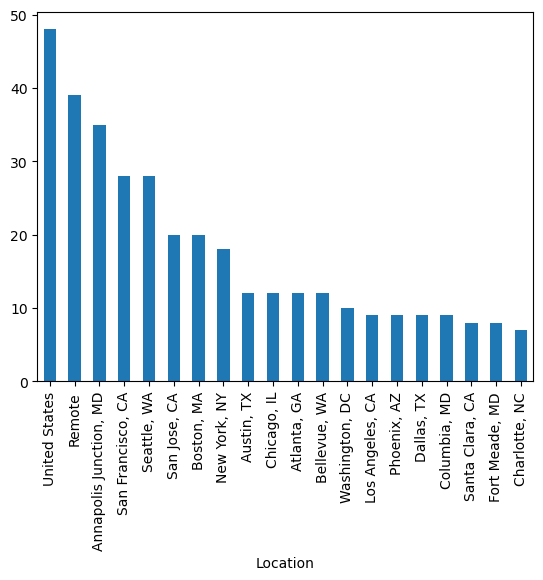

In [11]:
location_job_count = df.groupby('Location')['Job Title'].count()
top_20_locations = location_job_count.sort_values(ascending=False).head(20)
top_20_locations.plot.bar()

I found the number of job titles per locaiton listed. This bar graph is showing the top 20 locations with the most job titles listed. Suprsingly, most of them are generic like 'United States' and 'Remote.' 

### Scatter plot

<Axes: title={'center': 'Top 20 Locations: Job Count vs. Avg Company Score'}, xlabel='Job Count', ylabel='Avg Company Score'>

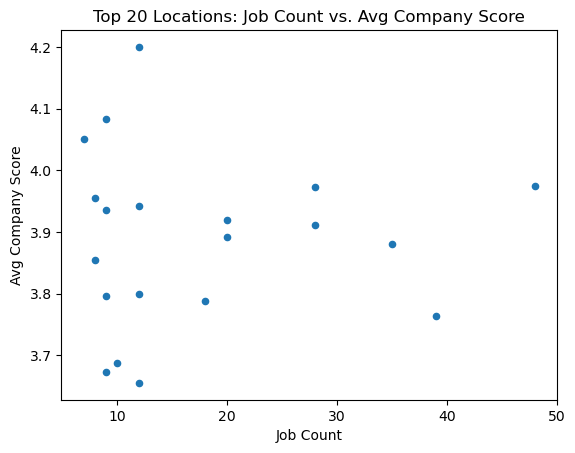

In [16]:
location_job_count = df.groupby('Location')['Job Title'].count()
top_20_locations = location_job_count.sort_values(ascending=False).head(20)
df_top_20 = df[df['Location'].isin(top_20_locations.index)]
location_avg_score = df_top_20.groupby('Location')['Company Score'].mean()
df_plot = pd.DataFrame({
    'Location': top_20_locations.index,
    'Job Count': top_20_locations.values,
    'Avg Company Score': location_avg_score.values
})
df_plot.plot(kind='scatter', x='Job Count', y='Avg Company Score', title="Top 20 Locations: Job Count vs. Avg Company Score")

This scatter plot is taking the orignal data from the bar graph above and comparing their average company scores. This is only showing the top 20 locations, and for each location what was the average company score. Each dot represents a location. Most locations that had about 10 job listings ranged from 3.5 to 4.2 but as the number of job counts increased it starts to level around 3.9. 

### Box Plot Outliers


<Axes: >

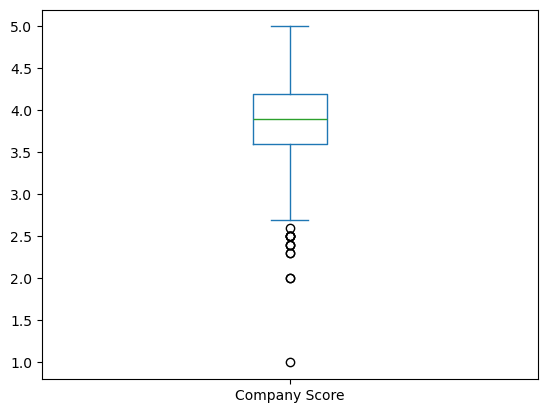

In [24]:
df['Company Score'].plot.box()

The outliers are companies that had a company score less than 2.5. Mean was around 4.0.

## Data Cleaning

In [28]:
df.head()

,Company,Company Score,Job Title,Location,Date,Salary
0,ViewSoft,4.8,Software Engineer,"Manassas, VA",8d,$68K - $94K (Glassdoor est.)
1,Workiva,4.3,Software Support Engineer,Remote,2d,$61K - $104K (Employer est.)
2,"Garmin International, Inc.",3.9,C# Software Engineer,"Cary, NC",2d,$95K - $118K (Glassdoor est.)
3,Snapchat,3.5,"Software Engineer, Fullstack, 1+ Years of Expe...","Los Angeles, CA",2d,$97K - $145K (Employer est.)
4,Vitesco Technologies Group AG,3.1,Software Engineer,"Seguin, TX",2d,$85K - $108K (Glassdoor est.)


In [30]:
df.isnull().sum()

Company            2
Company Score     81
Job Title          0
Location          13
Date               0
Salary           106
dtype: int64

In [32]:
df['Company Score']= df['Company Score'].fillna(df['Company Score'].mean())
df.isnull().sum()

Company            2
Company Score      0
Job Title          0
Location          13
Date               0
Salary           106
dtype: int64

In [34]:
missing_rows = df['Company'].isnull()
for index, row in df.iterrows():
    if pd.isnull(row['Company']):
        print(f"Missing value found at row: {index}")

Missing value found at row: 868
Missing value found at row: 869


In [36]:
df.shape

(870, 6)

In [38]:
df = df.drop(869)
df= df.drop(868)
df.shape

(868, 6)

In [40]:
df.isnull().sum()

Company            0
Company Score      0
Job Title          0
Location          13
Date               0
Salary           104
dtype: int64

In [42]:
unique_locations = df['Location'].unique()
unique_locations_list = unique_locations.tolist()
print(unique_locations_list)

['Manassas, VA', 'Remote', 'Cary, NC', 'Los Angeles, CA', 'Seguin, TX', 'New York, NY', 'Alpharetta, GA', 'Farmington Hills, MI', 'Boston, MA', 'San Francisco, CA', 'Aguadilla, PR', 'Minneapolis-Saint Paul', 'Plantation, FL', 'Northborough, MA', 'Seattle, WA', nan, 'Irving, TX', 'Springfield, MA', 'San Jose, CA', 'Bedford, MA', 'Sunrise, FL', 'Carlisle, PA', 'Annapolis Junction, MD', 'Lehi, UT', 'Mountain View, CA', 'Oxford, MA', 'Chicago, IL', 'Irvine, CA', 'Des Moines, IA', 'Phoenix, AZ', 'Renton, WA', 'Pittsburgh, PA', 'Dayton, OH', 'Cambridge, MA', 'United States', 'Morgantown, WV', 'Chantilly, VA', 'Burlington, VT', 'Bellevue, WA', 'Dublin, OH', 'Fremont, CA', 'Dallas, TX', 'Burlington, MA', 'Waterford, CT', 'Somerset, WI', 'Nashville, TN', 'Troy, MI', 'Barre, VT', 'Atlanta, GA', 'Melville, NY', 'Kennedy Sp Ct, FL', 'Dahlgren, VA', 'Stennis Space Center, MS', 'Eugene, OR', 'Utah', 'Newark, DE', 'Washington, DC', 'King of Prussia, PA', 'Morrisville, NC', 'Fort Meade, MD', 'Arlingto

In [44]:
df['Location']= df['Location'].fillna('United States')
df.isnull().sum()

Company            0
Company Score      0
Job Title          0
Location           0
Date               0
Salary           104
dtype: int64

In [46]:
def split_salary_col(val):
    data_source = ""
    pay = ""
    
    # Check for null and nan
    if val == None:
        val = ""

    # Convert value to lower case
    val = str(val)
    val = val.lower().replace("$", "")

    # Extract the "source" part of the value
    if val.find("(glassdoor est.)") != -1:
        data_source = "Glassdoor"
    elif val.find("(employer est.)") != -1:
        data_source = "Employer"
    else:
        data_source = "Unknown"

    # Extract the "pay per hour vs. salary" part of the value
    if val.find("per hour") != -1:
        pay = "hourly"
    else:
        pay = "salary"

    # Remove "source" part of the value
    val = str(val).replace("(glassdoor est.)", "").replace("(employer est.)", "").strip()

    # Remove "pay" part of the value
    val = val.replace("per hour", "")

    # Replace instances of letter 'k' with '000' to signify thousands
    val = val.replace("k", "000")
    
    # Split value into lower and upper range bounds
    temp = val.split("-")

    # Check if only the lower range exists.  If only lower range exists, duplicate it to upper range
    if len(temp) == 1:
        temp.append(temp[0])

    # Deal with blank or missing or NULL values
    for i in range(0, len(temp)):
        temp[i] = temp[i].strip().replace("nan", "0")
        if temp[i] == "":
            temp[i] = 0
    
    
    return data_source, pay, float(temp[0]), float(temp[1])

In [48]:
# Create new columns and initialize the values
df[['DataSource', 'Pay']] = ''
df[['IncomeLowerBound', 'IncomeUpperBound']] = 0.0

In [54]:
# Iterate through the DataFrame
for idx, row in df.iterrows():
    data = split_salary_col(row['Salary']) # This will return four values (employer, pay, lower range, upper range)
    df.at[idx, 'DataSource'] = data[0] # Data source refers to who reported the income - employer vs. glassdoor
    df.at[idx, 'Pay'] = data[1] # Hourly vs. salary
    df.at[idx, 'IncomeLowerBound'] = data[2] # Lower bound of the pay range
    df.at[idx, 'IncomeUpperBound'] = data[3] # Upper bound of the pay range

In [70]:
df

,Company,Company Score,Job Title,Location,Date,Salary,DataSource,Pay,IncomeLowerBound,IncomeUpperBound
0,ViewSoft,4.800000,Software Engineer,"Manassas, VA",8d,$68K - $94K (Glassdoor est.),Glassdoor,salary,68000.0,94000.0
1,Workiva,4.300000,Software Support Engineer,Remote,2d,$61K - $104K (Employer est.),Employer,salary,61000.0,104000.0
2,"Garmin International, Inc.",3.900000,C# Software Engineer,"Cary, NC",2d,$95K - $118K (Glassdoor est.),Glassdoor,salary,95000.0,118000.0
3,Snapchat,3.500000,"Software Engineer, Fullstack, 1+ Years of Expe...","Los Angeles, CA",2d,$97K - $145K (Employer est.),Employer,salary,97000.0,145000.0
4,Vitesco Technologies Group AG,3.100000,Software Engineer,"Seguin, TX",2d,$85K - $108K (Glassdoor est.),Glassdoor,salary,85000.0,108000.0
...,...,...,...,...,...,...,...,...,...,...
863,OpenAI,3.895311,Embedded Software Engineer (Entry-Level),"Lake Hopatcong, NJ",2d,NaN,Unknown,salary,0.0,0.0
864,"Akina, Inc.",3.895311,Senior Software Engineer - App Orchestration,"San Mateo, CA",30d+,NaN,Unknown,salary,0.0,0.0
865,RXO,3.895311,"Software Engineer, Machine Learning Compute","San Francisco, CA",6d,NaN,Unknown,salary,0.0,0.0
866,Infosys,3.895311,Software Engineer - 3 (Apache NiFi),"Annapolis Junction, MD",18d,NaN,Unknown,salary,0.0,0.0


To identify missing values, I used the isnull().sum()
I saw that the company had 2 missing, the company score had 81 missing, location had 13 missing, and salary had 106 missing. 
* For the company names there were missing I removed them from the dataset because there was only two and you cannot have a job without a company attached to it.
* For the company score I used mean value imputation
* for the location, I checked to make sure all locations were in the US to start and used most common value imputation which also happened to be the US
* for the salary I split it into 3 columns(pay type: salary/hourly, income lower bound, and income upper bound) if it was missing it listed it as unknown and the bounds were set to 0

## Summary Statistics & Relationships

In [75]:
df.describe()

,Company Score,IncomeLowerBound,IncomeUpperBound
count,868.000000,868.000000,868.000000
mean,3.895311,88664.071647,131697.693099
std,0.500464,50451.792958,78053.888330
min,1.000000,0.000000,0.000000
25%,3.600000,70000.000000,103000.000000
50%,3.895311,90000.000000,130000.000000
75%,4.100000,115000.000000,168000.000000
max,5.000000,343000.000000,637000.000000


In [79]:
df.dtypes

Company              object
Company Score       float64
Job Title            object
Location             object
Date                 object
Salary               object
DataSource           object
Pay                  object
IncomeLowerBound    float64
IncomeUpperBound    float64
dtype: object

In [81]:
df['Company'].value_counts().head(15)

Company
CVS Health                               9
BOEING                                   7
Adobe                                    7
OpenAI                                   7
Fanatics Inc.                            6
Microsoft                                6
Synergy ECP                              6
Garmin International, Inc.               6
Salesforce                               6
Innovative Defense Technologies (IDT)    5
WALGREENS                                5
Amex                                     5
Zoox                                     5
Honeywell                                5
State Street                             4
Name: count, dtype: int64

In [83]:
df['Job Title'].value_counts().head(15)

Job Title
Software Engineer                156
Senior Software Engineer          41
Software Engineer II              19
Software Developer                15
Software Engineer III             10
Sr. Software Engineer              9
DevOps Engineer                    9
Software Development Engineer      8
Sr Software Engineer               6
Software Engineer I                6
Associate Software Engineer        6
Cloud Engineer                     5
Junior Software Engineer           4
Software Engineers                 4
Staff Software Engineer            4
Name: count, dtype: int64

In [85]:
df['Location'].value_counts().head(15)

Location
United States             61
Remote                    39
Annapolis Junction, MD    35
San Francisco, CA         28
Seattle, WA               28
San Jose, CA              20
Boston, MA                19
New York, NY              18
Bellevue, WA              12
Atlanta, GA               12
Austin, TX                12
Chicago, IL               12
Washington, DC            10
Dallas, TX                 9
Phoenix, AZ                9
Name: count, dtype: int64

In [87]:
df['Date'].value_counts().head(15)

Date
30d+    206
2d       99
3d       83
4d       54
1d       53
5d       45
10d      40
6d       33
9d       33
12d      26
11d      26
18d      20
16d      18
17d      16
19d      15
Name: count, dtype: int64

In [89]:
df['Salary'].value_counts().head(15)

Salary
$120K - $150K (Employer est.)      5
$129K - $224K (Employer est.)      5
$120K - $140K (Employer est.)      4
$155K - $221K (Employer est.)      3
$160K - $385K (Employer est.)      3
$85K - $150K (Employer est.)       3
$108K - $216K (Employer est.)      3
$124K - $234K (Employer est.)      3
$98K - $209K (Employer est.)       3
$81K - $118K (Glassdoor est.)      3
$50.00 Per Hour (Employer est.)    3
$104K - $348K (Employer est.)      3
$130K - $160K (Employer est.)      2
$80K - $110K (Employer est.)       2
$98K - $145K (Glassdoor est.)      2
Name: count, dtype: int64

In [91]:
df['DataSource'].value_counts().head(15)

DataSource
Employer     436
Glassdoor    328
Unknown      104
Name: count, dtype: int64

In [93]:
df['Pay'].value_counts().head(15)

Pay
salary    844
hourly     24
Name: count, dtype: int64

* Anything below a 3.6 or above 4.1 company score is considered an outlier
* The top companies that have multiple job titles listed are mainly technology companies that are well known names
* The most in demand/listed job titles are versions of software engineer (senior, I, II, III, developer)
* Majority of jobs are listed as general (United Staes) or as remote work
* 206 jobs have been listed for more than a  month  either meaning that have not been taken down or have not been filled
* most companies do not list salary, could be because they hope people will still be interested
     * A lot of those were employer estimated

In [98]:
df.dtypes

Company              object
Company Score       float64
Job Title            object
Location             object
Date                 object
Salary               object
DataSource           object
Pay                  object
IncomeLowerBound    float64
IncomeUpperBound    float64
dtype: object

<Axes: title={'center': 'Company Score vs. Upper Bound Income'}, xlabel='Company Score', ylabel='IncomeUpperBound'>

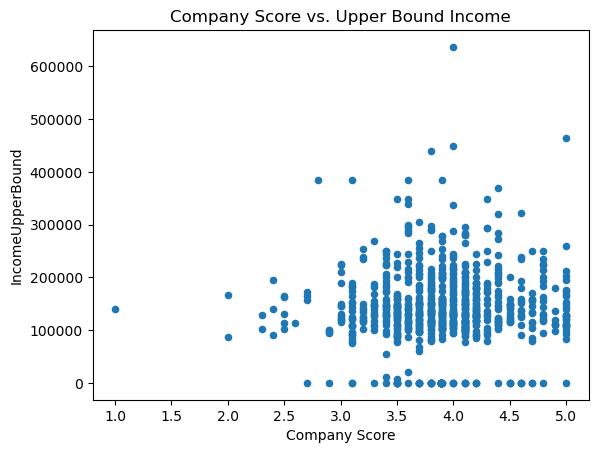

In [127]:
df.plot(kind='scatter', x='Company Score', y='IncomeUpperBound', title="Company Score vs. Upper Bound Income")

Those between 3.5 and 4.5 have a greater range of upper bound income. the closer you get to 5.0 the range decreases.

array([[<Axes: xlabel='Company Score', ylabel='Company Score'>,
        <Axes: xlabel='IncomeUpperBound', ylabel='Company Score'>,
        <Axes: xlabel='IncomeLowerBound', ylabel='Company Score'>],
       [<Axes: xlabel='Company Score', ylabel='IncomeUpperBound'>,
        <Axes: xlabel='IncomeUpperBound', ylabel='IncomeUpperBound'>,
        <Axes: xlabel='IncomeLowerBound', ylabel='IncomeUpperBound'>],
       [<Axes: xlabel='Company Score', ylabel='IncomeLowerBound'>,
        <Axes: xlabel='IncomeUpperBound', ylabel='IncomeLowerBound'>,
        <Axes: xlabel='IncomeLowerBound', ylabel='IncomeLowerBound'>]],
      dtype=object)

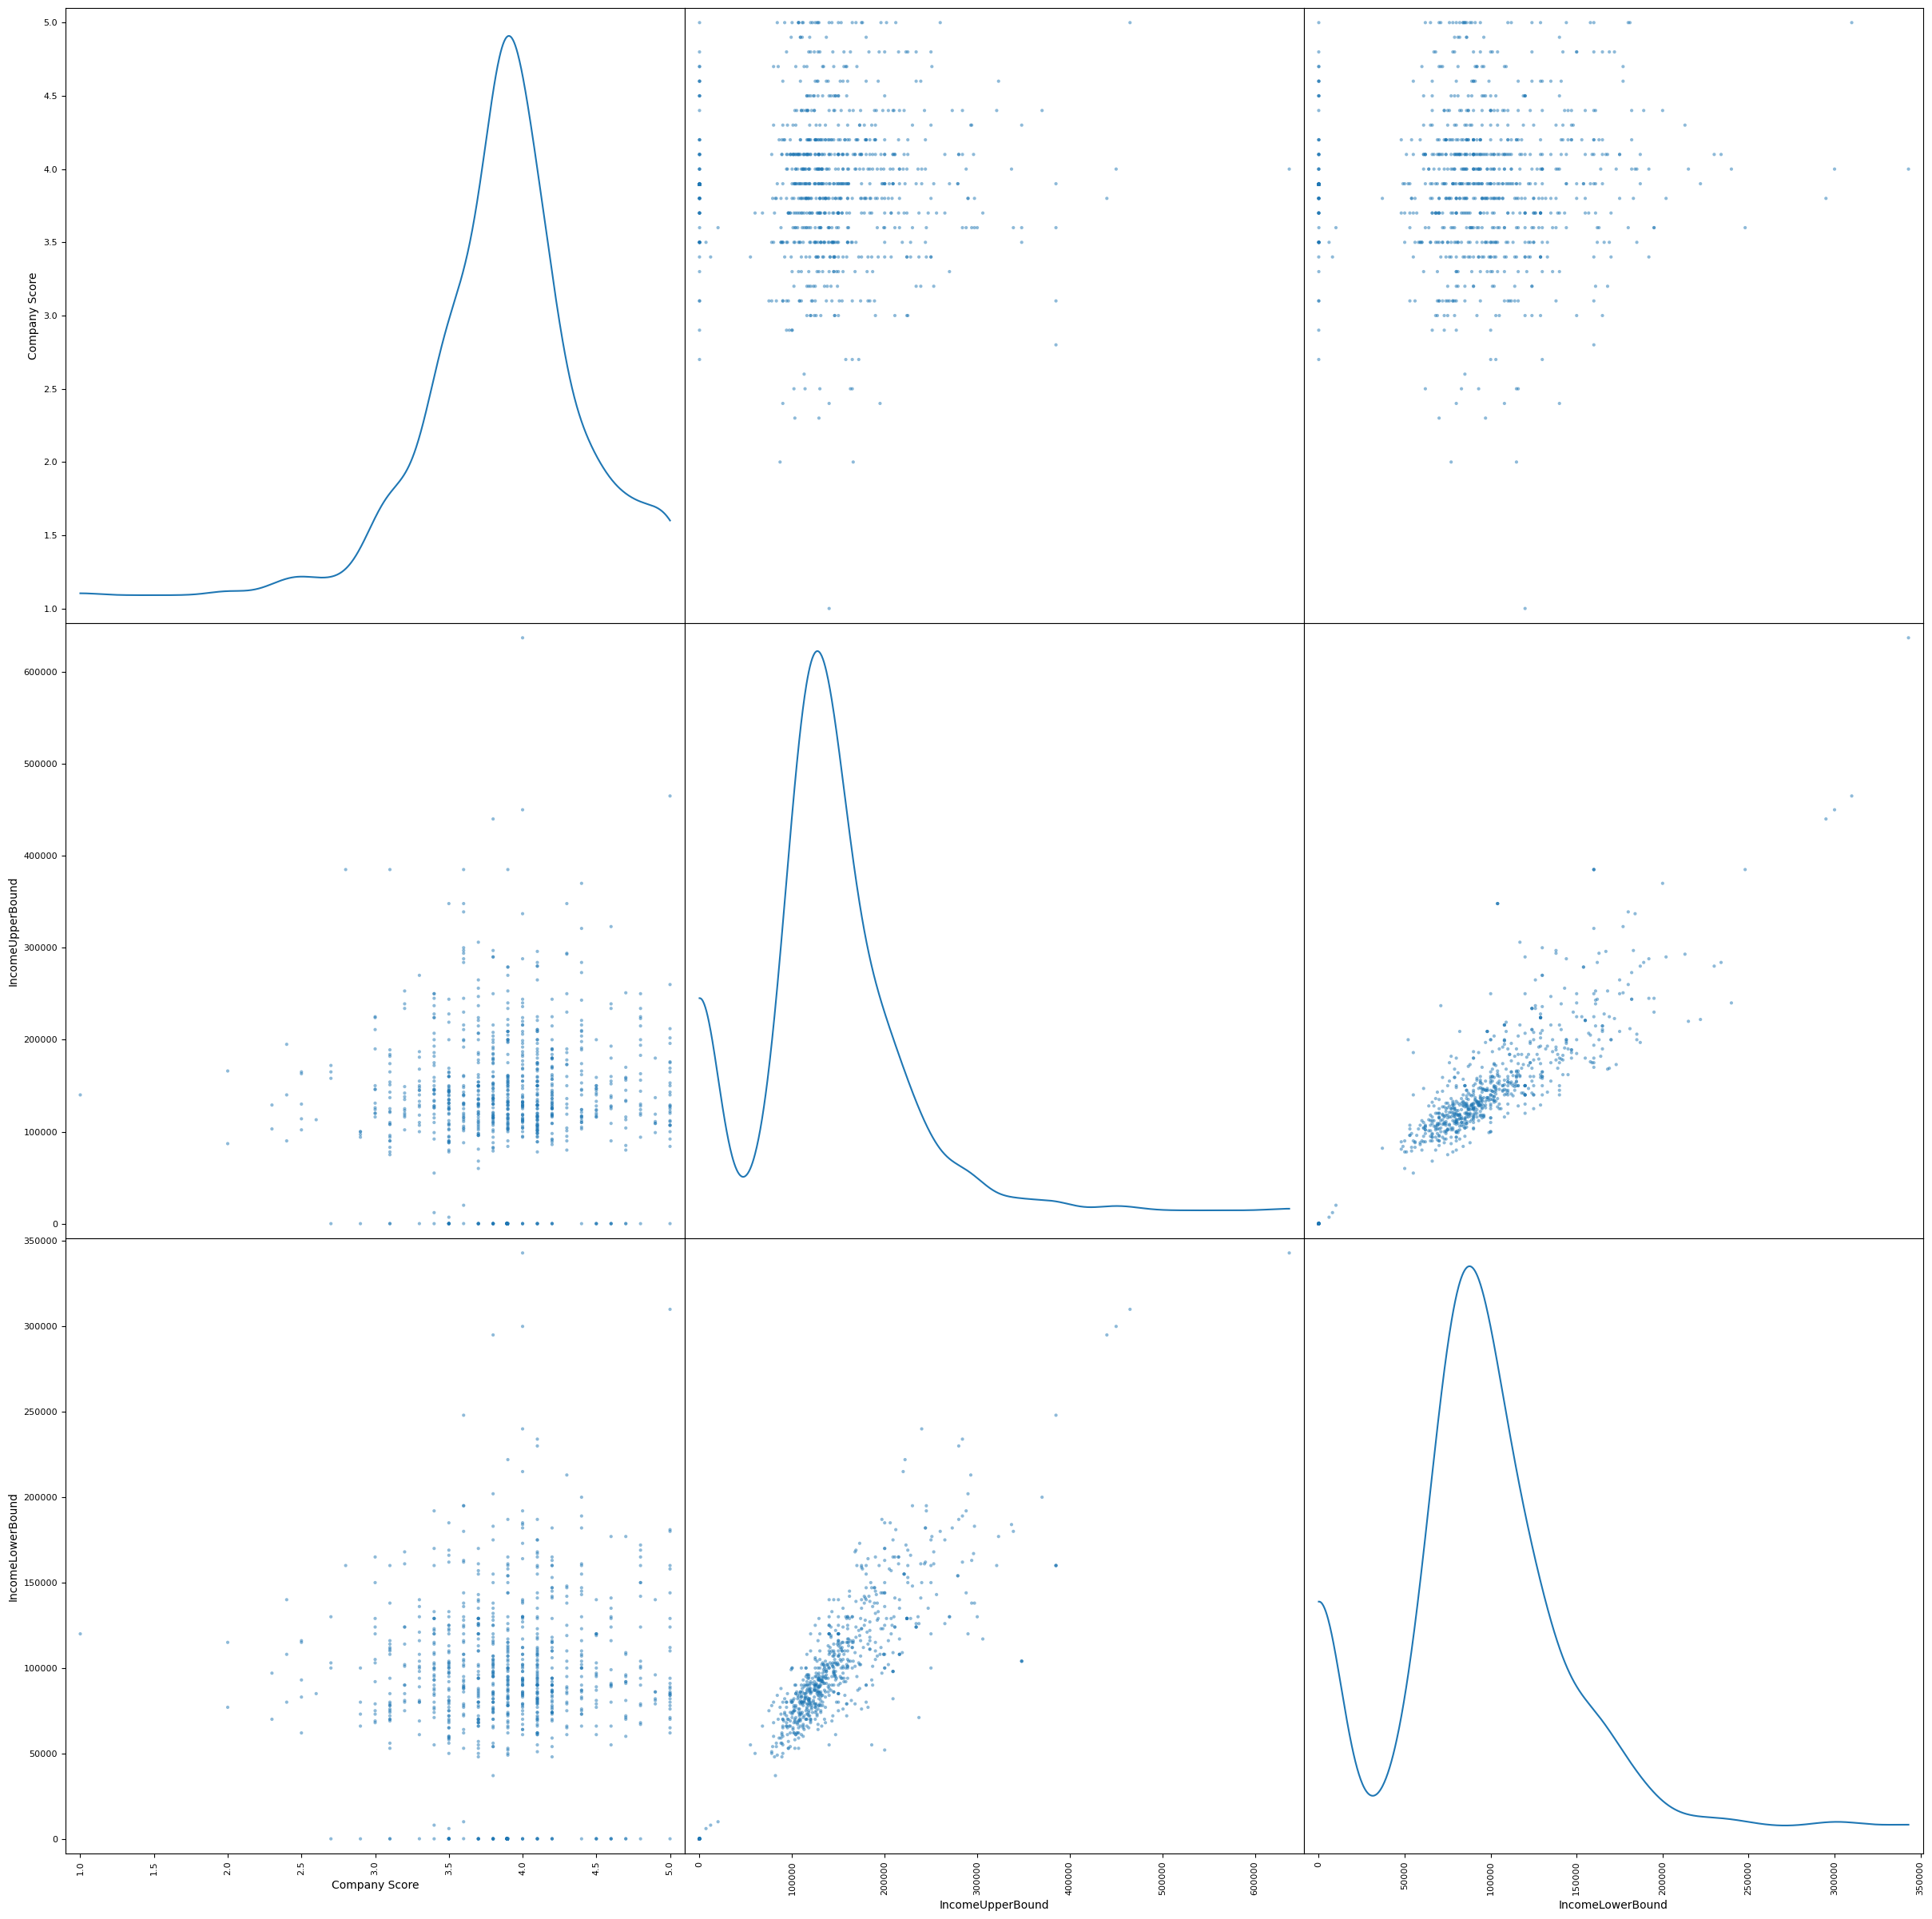

In [112]:
from pandas.plotting import scatter_matrix
scatter_matrix(df[['Company Score', 'IncomeUpperBound', 'IncomeLowerBound']], # Make a scatter matrix of all columns
               figsize=(30, 30), # Set plot size
               diagonal='kde')

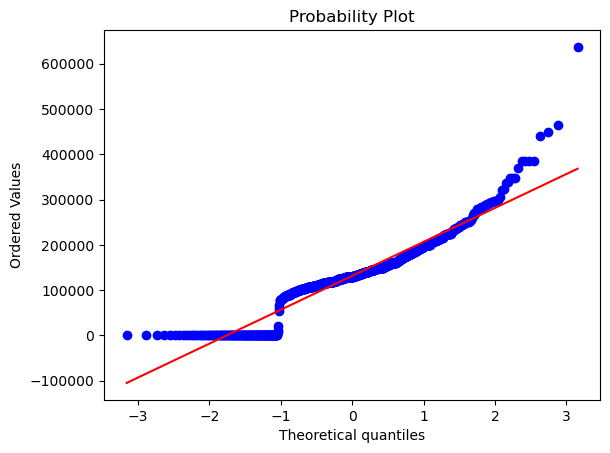

In [124]:
import pylab 
import scipy.stats as stats

stats.probplot(df["IncomeUpperBound"], dist="norm", plot=pylab)
pylab.show()

## Conclusion

From my analysis, several key findings stood out. First, even though all the locations in the dataset were within the United States, a majority were just labeled as 'United States' with no specific location. This could suggest a pattern of generalized job listings or a preference for remote positions since 'Remote' was the second most listed location. Another significant observation is that it's unusual for companies to be rated below 3.6 on a 5.0 scale, with such ratings being outliers on the bowplot. Companies that fall between 3.5 and 4.5 ratings tend to offer a broader range of upper-bound salaries. However, as the company rating approaches 5.0, the salary range tightens, indicating more consistency in compensation.

Furthermore, 156 job listings were for the position of "software engineer," reflecting either a high demand for this role or a trend of companies using similar titles for various levels of engineering roles. Additionally, when examining the relationship between the upper and lower salary bounds, the scatter plot revealed heteroscedasticity, suggesting that salary variability increases as you move up the income scale. This finding points to a potential disparity in how upper-bound salaries are determined relative to their lower-bound counterparts. These insights highlight patterns in job titles, compensation trends, and the consistency of company ratings.